# Multi-Head Attention

## The big picture

Multi-head attention is a **neural network layer that processes sequences of
tokens**.

### Tokens

A **token** is one element of a sequence, represented as a vector of $C$
numbers, called **channels**. Tokens can come from many different sources, for example:

* **text**: one token per word or piece of a word
* **images**: one token per image patch
* **robotics**: one token per robot state or action at a time step

### Input and output

In general, the layer has **three inputs**: **query tokens**, **key tokens** and
**value tokens**. Key token $j$ and value token $j$ form a pair: the key token
describes an item, and the value token holds its content. The query tokens
gather information from the value tokens, and decide how much to take from each
one by comparing themselves with the matching key tokens. This general form is
called **cross-attention**. For example, in a robot policy a few action tokens
(the query tokens) can gather information from many observation tokens (camera
patches, joint states).

$$\left.\begin{array}{r} X_q \in \mathbb{R}^{B \times T_q \times C_q} \\[4pt] X_k \in \mathbb{R}^{B \times T_k \times C_k} \\[4pt] X_v \in \mathbb{R}^{B \times T_k \times C_v} \end{array}\right\} \quad\longrightarrow\quad \text{multi-head attention} \quad\longrightarrow\quad Y \in \mathbb{R}^{B \times T_q \times C_q}$$

| Dimension | Meaning |
|---|---|
| $B$ | batch size: number of sequences in each input |
| $T_q$ | number of query tokens in each sequence of $X_q$ |
| $T_k$ | number of key tokens, and of value tokens, in each sequence of $X_k$ and $X_v$ |
| $C_q$, $C_k$, $C_v$ | channels of each query token, key token and value token |

* $B$ must be the same for all three inputs: query sequence $b$ is paired with
  key sequence $b$ and value sequence $b$.
* $X_k$ and $X_v$ must have the same number of tokens $T_k$, because key token
  $j$ and value token $j$ form a pair.
* Everything else can differ: $T_q$ and $T_k$, and the channel counts $C_q$,
  $C_k$ and $C_v$.

The output follows the queries: output token $Y_{b,t}$ is an updated version of
query token $(X_q)_{b,t}$, with the same $C_q$ channels, enriched with
information from the value tokens of sequence $b$. The key and value tokens
only provide information; the layer returns nothing for them.

**How information is mixed:**

* **From the value tokens to the query tokens: yes.** Each output token
  combines information from all value tokens of its sequence. How much it takes
  from each one is computed from the content of the query token and of the
  matching key token.
* **Between the query tokens: no.** Each query token gathers information on
  its own and never sees the other query tokens.
* **Between the channels of a token: yes.** Learned weight matrices mix the
  channels of each token. The same weights are used for every token of the
  same input.
* **Between the sequences of a batch: never.** Each set of sequences is
  processed independently. Batching only makes the computation faster.
* **Order is ignored.** Despite the word "sequence", the layer does not use the
  order of the tokens: shuffling the key/value pairs leaves the output
  unchanged, and shuffling the query tokens just shuffles the output tokens in
  the same way. Models that need order add it to the tokens beforehand
  (positional encodings).

### Self-attention

The most common use of the layer is a special case, **self-attention**: the
same tokens are used as query, key and value tokens, $X_q = X_k = X_v = X$. Each sequence then has
$T_q = T_k = T$ tokens with $C_q = C_k = C_v = C$ channels, and the layer takes a
batch of token sequences and outputs a modified batch of token sequences **of
the same shape**:

$$X \in \mathbb{R}^{B \times T \times C} \quad\longrightarrow\quad \text{multi-head attention} \quad\longrightarrow\quad Y \in \mathbb{R}^{B \times T \times C}$$

Output token $Y_{b,t}$ is an updated version of input token $X_{b,t}$. Because
every token is a query token, a key token and a value token, the tokens of a
sequence gather information **from each other**: each output token combines
information from all tokens of its sequence, and every token decides for
itself, based on content, which tokens are relevant to it.

---
# Part 0: Setup

Imports, and a small helper that prints a tensor's shape and checks it against
the shape we expect.

In [2]:
import math

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torch.nn as nn

torch.manual_seed(0)
torch.set_printoptions(precision=3, sci_mode=False)

In [3]:
def check_shape(name, t, expected, symbols=""):
    # Print a tensor's shape (and optionally its symbolic shape), and assert it matches.
    print(f"{name:<10} {str(tuple(t.shape)):<16} {symbols}")
    assert tuple(t.shape) == tuple(expected), f"{name}: expected {tuple(expected)}, got {tuple(t.shape)}"

---
# Part 1: Scaled dot-product attention

Scaled dot-product attention is the core operation inside multi-head attention.
It has **no learned parameters**:

$$
\boxed{\;\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V\;}
$$

In PyTorch it is implemented by
[`torch.nn.functional.scaled_dot_product_attention(query, key, value)`](https://pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html).

### Queries, keys and values

The operation works on three sets of tensors:

* **Queries**: what each output is *looking for*. There is one output per query.
* **Keys**: a *description* of each item that can be looked up. Each query is
  compared with every key to decide how relevant that item is.
* **Values**: the *content* of each item, i.e. what gets returned when the item
  is selected. Keys and values come in pairs: key $j$ describes value $j$.

### What it computes

For each query:

1. **Score** every key by how similar it is to the query (the dot product
   $q \cdot k_j$, divided by $\sqrt{d_k}$).
2. Turn the scores into **weights** with a softmax: all positive, summing to 1.
3. Return the **weighted average of the values**.

So each output is a blend of the values whose keys best match the query.

**Intuition: a soft dictionary lookup.**

* A Python `dict` compares the query to each key for **exact** equality and
  returns **one** value.
* Attention compares the query to **every** key with a **similarity score**,
  and returns a **weighted average** of all values.

*Example:* a robot's query describes its current situation, the keys describe
the situations at past time steps, and the values hold what the robot did at
those time steps. The output blends the past actions, giving the most weight to
time steps that looked like the current one.

### Shapes

For a single sequence (the batch dimension is added in 1.4):

| Matrix | Shape | Rows | Columns (channels) |
|---|---|---|---|
| $Q$ | $(T_q, d_k)$ | one per query | $d_k$ |
| $K$ | $(T_k, d_k)$ | one per key | $d_k$, must match $Q$ so that query–key dot products are defined |
| $V$ | $(T_k, d_v)$ | one per value, as many as keys | $d_v$, can differ from $d_k$ |
| output | $(T_q, d_v)$ | one per query | $d_v$, same as the values |

## 1.1 Query and key similarity scores

**Idea:** measure how well each query matches each key.

**Math:** let $q$ and $k$ be row vectors with $d_k$ channels, corresponding to
a single query and a single key. The similarity between them is their dot
product:

$$s = q \cdot k = \sum_{c=1}^{d_k} q_c \, k_c = q \, k^\top$$

Geometrically $q \cdot k = \lVert q \rVert \, \lVert k \rVert \cos\theta$: the score is
large and positive when $q$ and $k$ point the same way, 0 when they are
orthogonal, and negative when they are opposite. It depends on both
**direction** and **length**.

**All scores at once.** If we stack $T_q$ query vectors we get a query matrix $Q$. Similarly $K$ is matrix of $T_k$ stacked keys. We can calculate the similarity matrix between queries and keys as:

$$S = Q K^\top$$

$$
\begin{array}{ccccc}
Q & & K^\top & & S \\[4pt]
T_q\left\{\vphantom{\rule[-1.125em]{0pt}{2.25em}}\right.
\underbrace{\left[\phantom{\rule[-1.125em]{1.8em}{2.25em}}\right]}_{d_k}
& \times &
d_k\left\{\vphantom{\rule[-0.9em]{0pt}{1.8em}}\right.
\underbrace{\left[\phantom{\rule[-0.9em]{2.7em}{1.8em}}\right]}_{T_k}
& = &
T_q\left\{\vphantom{\rule[-1.125em]{0pt}{2.25em}}\right.
\underbrace{\left[\phantom{\rule[-1.125em]{2.7em}{2.25em}}\right]}_{T_k}
\end{array}
$$

* We call $S$ the **raw scores** (or **unscaled attention logits**).
* **Row $i$** of $S$ holds the scores of query $i$ against every key.
* **Column $j$** of $S$ holds the scores of key $j$ against every query.
* The score values in the similarity matrix are real values that can be either poisitive or negative.


## 1.2 Attention weights

**Goal:** for each query, turn its row of raw scores into **attention weights**:
positive numbers that sum to 1 and say how much the query takes from each key.

This takes two steps:

1. **Scale** the raw scores by $1/\sqrt{d_k}$. The result is the **attention logits** $\tilde{S}$.
2. Apply a **softmax** to each row of the logits. The result is the **attention weights** $A$.

$$S = Q K^\top, \qquad \tilde{S} = \frac{QK^\top}{\sqrt{d_k}}, \qquad A = \text{softmax}(\frac{QK^T}{\sqrt{d_k}})$$

Note that softmax is applied to each row of the attention logit matrix:

$$A_{ij} = \frac{e^{\tilde{S}_{ij}}}{\sum_{j'=1}^{T_k} e^{\tilde{S}_{ij'}}}$$


| Term | Symbol | Formula | Shape | Meaning |
|---|---|---|---|---|
| raw scores (unscaled attention logits) | $S$ | $QK^\top$ | $(T_q, T_k)$ | dot-product similarity of each query–key pair; any real number |
| attention logits | $\tilde{S}$ | $S / \sqrt{d_k}$ | $(T_q, T_k)$ | scaled scores; the input to the softmax |
| attention weights (attention matrix) | $A$ | $\text{softmax}(\tilde{S})$, per row | $(T_q, T_k)$ | positive; each row sums to 1 |

### Why scale by $\sqrt{d_k}$

**1. The larger $d_k$, the larger the spread of the raw scores.** Each raw score
is a sum of $d_k$ products:

$$S_{ij} = \sum_{c=1}^{d_k} q_{i,c} \, k_{j,c}$$

Assume the entries of the queries and keys are drawn from a Gaussian distributoin with mean 0 and
variance 1. Then

$$\mathbb{E}[S_{ij}] = 0, \qquad
\text{Var}(S_{ij}) = \sum_{c=1}^{d_k} \text{Var}(q_{i,c} \, k_{j,c}) = \sum_{c=1}^{d_k} \mathbb{E}[q_{i,c}^2]\,\mathbb{E}[k_{j,c}^2] = d_k$$

The **average** score stays 0, but the **variance** grows with $d_k$ (the
standard deviation grows as $\sqrt{d_k}$). So the larger the dimension of the key vector $d_k$, the more likely it is that one of the elements in the raw score vector will have a value that is significantly larger than the values of all other elements in the vector.

**2. Large positive values break the softmax.** The softmax exponentiates the
logits, so differences between them get amplified: two logits that differ by
$\Delta$ get weights in the ratio $e^{\Delta}$. If a row happens to contain one
value much larger than the others, the softmax gives almost all the weight to
it, and that row of $A$ becomes nearly **one-hot**. This causes two problems:

* The query attends to a single key and ignores the others.
* **Gradients vanish.** The gradient of the softmax is
  $\frac{\partial A_{ij}}{\partial \tilde{S}_{ij'}} = A_{ij}(\delta_{jj'} - A_{ij'})$.
  When the row is one-hot, every term is ≈ 0 (either $A \approx 1$ times
  $1 - A \approx 0$, or a product with some $A \approx 0$). The logits then get
  almost no gradient, and learning stalls.

There is nothing wrong with attention weights that are close to one-hot, as long as that sharpness is learned because a query really matches one key. It should not be a side effect of the dimension $d_k$ of the queries and keys.

In [8]:
s = torch.tensor([1.0, 2.0, 3.0, 0.5, 0.0, -1.0])
for c in [0.1, 1.0, 10.0]:
    print(f"softmax({c:>4} * s) = {torch.softmax(c * s, dim=-1)}")

softmax( 0.1 * s) = tensor([0.167, 0.184, 0.204, 0.159, 0.151, 0.136])
softmax( 1.0 * s) = tensor([0.082, 0.222, 0.605, 0.050, 0.030, 0.011])
softmax(10.0 * s) = tensor([    0.000,     0.000,     1.000,     0.000,     0.000,     0.000])


**3. Fix: make the variance of the logits independent of $d_k$.** We want the
logits to have the same variance no matter how large $d_k$ is. Since
$\text{Var}(a X) = a^2 \, \text{Var}(X)$, dividing the raw scores by $\sqrt{d_k}$ gives

$$\text{Var}\left(\frac{S_{ij}}{\sqrt{d_k}}\right) = \frac{\text{Var}(S_{ij})}{d_k} = \frac{d_k}{d_k} = 1$$

This is exactly the scaling in $\tilde{S} = S / \sqrt{d_k}$. (Dividing the
logits by a constant $\tau$ before a softmax is also called using a softmax
**temperature** $\tau$. Here $\tau = \sqrt{d_k}$.)

**Experiment:** for increasing $d_k$, measure the standard deviation of the raw
scores and of the logits, and the average largest attention weight
(1 = one-hot, $1/T_k$ = uniform), with and without scaling. Without scaling, the softmax becomes nearly one-hot as $d_k$ grows. With
scaling, its sharpness does not depend on $d_k$.

  d_k sqrt(d_k) |  std raw std scaled | max w raw max w scaled
    4      2.00 |     2.01       1.01 |     0.420        0.233
   16      4.00 |     3.97       0.99 |     0.685        0.241
   64      8.00 |     7.96       1.00 |     0.851        0.249
  256     16.00 |    16.01       1.00 |     0.926        0.249
 1024     32.00 |    31.98       1.00 |     0.963        0.246


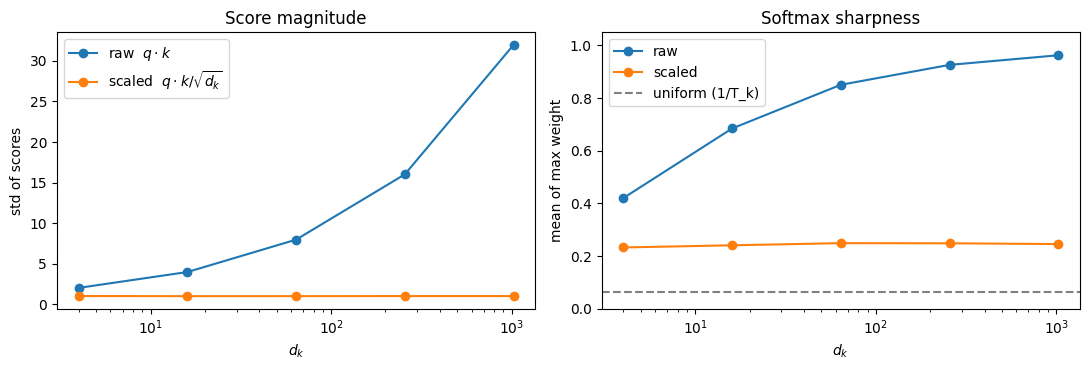

In [9]:
dims = [4, 16, 64, 256, 1024]
n_keys, n_trials = 16, 2000

rows = []
for d in dims:
    q = torch.randn(n_trials, 1, d)        # one query per trial
    k = torch.randn(n_trials, n_keys, d)
    s = q @ k.transpose(-2, -1)            # (n_trials, 1, n_keys)
    s_scaled = s / math.sqrt(d)
    rows.append((
        d,
        s.std().item(),
        s_scaled.std().item(),
        torch.softmax(s, dim=-1).max(dim=-1).values.mean().item(),
        torch.softmax(s_scaled, dim=-1).max(dim=-1).values.mean().item(),
    ))

print(f"{'d_k':>5} {'sqrt(d_k)':>9} | {'std raw':>8} {'std scaled':>10} | {'max w raw':>9} {'max w scaled':>12}")
for d, sr, ss, mr, ms in rows:
    print(f"{d:>5} {math.sqrt(d):>9.2f} | {sr:>8.2f} {ss:>10.2f} | {mr:>9.3f} {ms:>12.3f}")

_, std_raw, std_scaled, maxw_raw, maxw_scaled = zip(*rows)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(dims, std_raw, "o-", label="raw  $q\\cdot k$")
axes[0].plot(dims, std_scaled, "o-", label="scaled  $q\\cdot k/\\sqrt{d_k}$")
axes[0].set(xscale="log", xlabel="$d_k$", ylabel="std of scores", title="Score magnitude")
axes[1].plot(dims, maxw_raw, "o-", label="raw")
axes[1].plot(dims, maxw_scaled, "o-", label="scaled")
axes[1].axhline(1 / n_keys, ls="--", c="gray", label="uniform (1/T_k)")
axes[1].set(xscale="log", xlabel="$d_k$", ylabel="mean of max weight", title="Softmax sharpness", ylim=(0, 1.05))
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

### Numerically stable softmax

**Problem:** computing the softmax formula directly can fail numerically. In
`float32`, $e^{x}$ overflows to `inf` for $x \gtrsim 89$, and `inf / inf = nan`.
In the other direction, if all logits in a row are very negative, every
$e^{x}$ underflows to 0 and the result is `0 / 0 = nan`.

**Fix:** subtract the row maximum $m_i = \max_{j'} \tilde{S}_{ij'}$ before
exponentiating. This does not change the result, because the factor
$e^{-m_i}$ cancels out (the softmax is **shift invariant**):

$$\frac{e^{\tilde{S}_{ij} - m_i}}{\sum_{j'} e^{\tilde{S}_{ij'} - m_i}}
= \frac{e^{-m_i} \, e^{\tilde{S}_{ij}}}{e^{-m_i} \sum_{j'} e^{\tilde{S}_{ij'}}}
= A_{ij}$$

After the shift, the largest exponent in each row is $e^0 = 1$, so nothing
overflows, and the denominator is at least 1, so there is no division by 0.

`torch.softmax` does this internally. In attention it is applied over the last
dimension, the keys: `torch.softmax(S_tilde, dim=-1)`. Using `dim=0` would
normalize over *queries*, which is wrong.

In [10]:
def softmax_naive(S_tilde):
    E = torch.exp(S_tilde)
    return E / E.sum(dim=-1, keepdim=True)


def softmax_rows(S_tilde):
    # Numerically stable softmax over the last dimension (the keys)
    m = S_tilde.max(dim=-1, keepdim=True).values   # row maximum, shape (..., 1)
    E = torch.exp(S_tilde - m)
    return E / E.sum(dim=-1, keepdim=True)


logits = torch.tensor([[1000.0, 1001.0, 1002.0]])
print("naive :", softmax_naive(logits))
print("stable:", softmax_rows(logits))

# Same result as PyTorch
x = 10 * torch.randn(5, 6)
assert torch.allclose(softmax_rows(x), torch.softmax(x, dim=-1))

naive : tensor([[nan, nan, nan]])
stable: tensor([[0.090, 0.245, 0.665]])


## 1.3 Attention outputs

**Idea:** a key and a value form a key-value pair. The key is used to decide *how much* a query
takes from the corresponding value. Since we have multiple key-value pairs, the output for a
query blends the values from all key-value pairs, using that query's attention weights.

**Math:** value $j$ is row $j$ of $V$. The output for query $i$ is

$$o_i = \sum_{j=1}^{T_k} A_{ij} \, v_j$$

Stacking the outputs as the rows of $O$ turns this into a single matrix product
and completes the scaled dot-product attention formula:

$$O = AV = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V$$

$$
\begin{array}{ccccc}
A & & V & & O \\[4pt]
T_q\left\{\vphantom{\rule[-1.125em]{0pt}{2.25em}}\right.
\underbrace{\left[\phantom{\rule[-1.125em]{2.7em}{2.25em}}\right]}_{T_k}
& \times &
T_k\left\{\vphantom{\rule[-1.35em]{0pt}{2.7em}}\right.
\underbrace{\left[\phantom{\rule[-1.35em]{3.15em}{2.7em}}\right]}_{d_v}
& = &
T_q\left\{\vphantom{\rule[-1.125em]{0pt}{2.25em}}\right.
\underbrace{\left[\phantom{\rule[-1.125em]{3.15em}{2.25em}}\right]}_{d_v}
\end{array}
$$

* The columns of $A$ and the rows of $V$ both have size $T_k$: there is one
  weight for each key–value pair.
* $O$ has one row per query ($T_q$) and $d_v$ columns. The size of each output
  is set by the values, not by the queries or keys.
* **A weighted average, not just any linear combination.** Each row of $A$ is
  positive and sums to 1, so each output always lies "between" the values. In
  the extreme cases:
  * one-hot weights → the output is exactly one value (a hard lookup, like a `dict`)
  * uniform weights → the output is the mean of all values
* **Queries don't interact.** Output $i$ depends only on row $i$ of $A$, so all
  queries are computed independently, in parallel, and adding a query doesn't
  change the other outputs.
* **Values enter linearly; queries and keys don't.** $Q$ and $K$ affect the
  output only through the softmax weights, while $V$ is mixed in directly.

In [11]:
def softmax_stable(X):
    """Stable softmax function over rows of a tensor.
    
    Args:
        X: Input matrix of shape (...)

    Returns:
        Softmax applied over the last dimension (rows) of X.
    """
    X_max = X.max(dim=-1, keepdim=True).values              # Calculate row-wise max. dim=-1 is the last dimension which is always rows for any matrix
    exponents = torch.exp(X - X_max)                        # Subtract the row-wise max before exponentiating
    exponents_sum = exponents.sum(dim=-1, keepdim=True)     # Sum exponents over rows

    return exponents / exponents_sum


def scaled_dot_product_attention(Q, K, V):
    """Compute scaled dot-product attention.

    Inputs:
        Q: query tensor
        K: key tensor
        V: value tensor

    Algorithm:
        A = softmax(QK^T / sqrt(d_k))   # softmax is row-wise     
                                        # d_k is the number of rows in QK^T or number of columns in Q and K
        O = AV

    Tensor shapes:
        Q: shape (..., T_q, d_k)
        K: shape (..., T_k, d_k)
        V: shape (..., T_k, d_v)

        QK^T:   shape (..., T_q, T_k)
        A:      shape (..., T_q, T_k)
        O:      shape (..., T_q, d_v)

    Args:
        Q: Query matrix of shape (..., T_q, d_k)
        K: Key matrix of shape (..., T_k, d_k)
        V: Value matrix of shape (..., T_k, d_v)

    Returns:
        Output matrix after applying attention weights to V, shape (..., T_q, d_v)
    """

    d_k = K.shape[-1]               # Last element in the shape vector is number of columns
    S = Q @ K.transpose(-2, -1)     # (..., T_q, T_k) Raw logits (unscaled)
    S_tilde = S / math.sqrt(d_k)    # (..., T_q, T_k) Scaled logits
    A = softmax_stable(S_tilde)     # (..., T_q, T_k) Attention weights

    return A @ V     # (..., T_q, d_v)

In [12]:
# Validate our implementation of the scaled dot product attention against PyTorch's built-in implementation.

T_q = 3
T_k = 4
d_k = 5
d_v = 6

for B in [2, 4, 8]:
    Q = torch.randn(B, T_q, d_k)
    K = torch.randn(B, T_k, d_k)
    V = torch.randn(B, T_k, d_v)
    O_ours = scaled_dot_product_attention(Q, K, V)
    O_torch = F.scaled_dot_product_attention(Q, K, V)
    check_shape("O", O_ours, (B, T_q, d_v), "(B, T_q, d_v)")
    print(f"B={B}: max |ours - torch| = {(O_ours - O_torch).abs().max():.2e}")
    assert torch.allclose(O_ours, O_torch, atol=1e-6)

O          (2, 3, 6)        (B, T_q, d_v)
B=2: max |ours - torch| = 1.79e-07
O          (4, 3, 6)        (B, T_q, d_v)
B=4: max |ours - torch| = 2.38e-07
O          (8, 3, 6)        (B, T_q, d_v)
B=8: max |ours - torch| = 2.38e-07


## 1.4 Computational complexity

**Cost of a matrix product.** Multiplying an $(n, m)$ matrix by an $(m, p)$
matrix takes $n \cdot m \cdot p$ multiply-adds: the result has $n \cdot p$
entries, and each entry is a dot product of length $m$ (see
`matrix_multiplication.ipynb`).

**Cost of each step**, for one sequence:

| Step | Shapes | Multiply-adds | Size of the result |
|---|---|---|---|
| raw scores $S = QK^\top$ | $(T_q, d_k) \; @ \; (d_k, T_k)$ | $T_q \cdot T_k \cdot d_k$ | $T_q \cdot T_k$ |
| attention logits $\tilde{S} = S / \sqrt{d_k}$ | element-wise | $T_q \cdot T_k$ | $T_q \cdot T_k$ |
| attention weights $A = \text{softmax}(\tilde{S})$ | a few passes over each row | $\sim T_q \cdot T_k$ | $T_q \cdot T_k$ |
| attention outputs $O = AV$ | $(T_q, T_k) \; @ \; (T_k, d_v)$ | $T_q \cdot T_k \cdot d_v$ | $T_q \cdot d_v$ (doesn't count since this is output)|

**Time complexity**

$$O\big(T_q \cdot T_k \cdot (d_k + d_v)\big)$$

The two matrix products dominate the computation. With a batch, everything is
multiplied by $B$ (and by any other leading dimensions).

**Space complexity**

Space complexity measures the **peak memory** an algorithm needs **in addition
to its inputs and outputs**: the largest amount of extra memory in use at the
same time. The inputs ($Q$, $K$, $V$) and the output ($O$) are not counted,
because every way of computing attention needs them.

Here, the extra memory holds the intermediate results $S$, $\tilde{S}$ and $A$,
each a $T_q \times T_k$ matrix. At least one of them must exist in full: $A$ has
to be complete before $O = AV$ can be computed. A straightforward implementation
keeps a few of them at the same time, but a constant number of matrices does not
change the big O:

$$O(T_q \cdot T_k)$$

The output, of size $T_q \cdot d_v$, does not appear because it is not extra
memory. (With only a few keys, i.e. a small $T_k$, the output can even be larger
than the attention matrix.) With a batch, the memory is multiplied by $B$.

**Self-attention**

In self-attention ($T_q = T_k = T$, $d_k = d_v = d$). The computational complexity becomes $O(T^2 \cdot d)$
  time and $O(T^2)$ memory: it is **quadratic in the sequence length**.
  Doubling $T$ makes attention 4 times more expensive and the attention matrix
  4 times larger. This is the main limitation of attention for long sequences.
  The cost is only linear in $d$.

**Flash attention**

FlashAttention computes exactly the same result as scaled dot-product attention,
but processes the keys and values in small blocks and never stores the full
$T_q \times T_k$ attention matrix.

* **Memory: reduced** from $O(T_q \cdot T_k)$ to $O(T_q)$ extra memory: only a
  small block of scores at a time, plus two running numbers per query. This is
  linear in the sequence length.
* **Computation: unchanged.** Every query is still compared with every key:
  $O(T_q \cdot T_k \cdot d)$.

**Why it is still faster:** on a GPU, attention is limited less by the
arithmetic than by moving the large intermediate matrices to and from the slow
main GPU memory. FlashAttention keeps each block in fast on-chip memory, which
avoids most of this traffic. `F.scaled_dot_product_attention` uses it
automatically on supported GPUs.

---
# Part 2: Single-head attention

In Part 1, the queries, keys and values used in the scaled dot-product attention were given. In an attention layer they
are computed from the input tokens. This part builds the complete layer for
the simplest case, a **single head**.

The layer takes three batches of token sequences, the query, key and value
tokens, and returns one output token for every query token:

$$\left.\begin{array}{r} X_q \in \mathbb{R}^{B \times T_q \times C_q} \\[4pt] X_k \in \mathbb{R}^{B \times T_k \times C_k} \\[4pt] X_v \in \mathbb{R}^{B \times T_k \times C_v} \end{array}\right\} \quad\longrightarrow\quad Y \in \mathbb{R}^{B \times T_q \times C_q}$$

It has three steps:

1. **Input projections:** learned matrices $W_q$, $W_k$ and $W_v$ compute a
   query from every query token, a key from every key token and a value from
   every value token (2.1).
2. **Scaled dot-product attention** from Part 1 computes the attention outputs.
3. **Output projection:** a learned matrix $W_o$ maps the attention outputs back
   to $C_q$ channels, the channels of the query tokens (2.2).

$$Y = \text{softmax}\!\left(\frac{(X_q W_q)(X_k W_k)^\top}{\sqrt{d_k}}\right) (X_v W_v) \, W_o$$

The four matrices $W_q$, $W_k$, $W_v$ and $W_o$ are the **learned parameters**
of the attention layer.

**Self-attention** is the special case $X_q = X_k = X_v = X$, with $C$ channels:
the output has the same shape as the input.

$$X \in \mathbb{R}^{B \times T \times C} \quad\longrightarrow\quad Y \in \mathbb{R}^{B \times T \times C}$$

$$Y = \text{softmax}\!\left(\frac{(XW_q)(XW_k)^\top}{\sqrt{d_k}}\right) (XW_v) \, W_o$$

Sections 2.1–2.4 build the layer in its general form, and 2.5 looks at
self-attention.

## 2.1 Queries, keys and values from tokens

**Idea:** every query token is turned into a query, every key token into a
key and every value token into a value, by multiplying them with three learned
matrices $W_q$, $W_k$ and $W_v$. Each matrix is used for every token of its
input.

**Math:** with the tokens of one sequence as the rows of $X_q$, $X_k$ and $X_v$:

$$Q = X_q W_q, \qquad K = X_k W_k, \qquad V = X_v W_v$$

Row $t$ of $Q$ is the query of query token $t$: $q_t = (x_q)_t W_q$. Likewise, row $j$
of $K$ is the key of key token $j$, and row $j$ of $V$ is the value of value
token $j$.

$$
\begin{array}{ccccc}
X_q & & W_q & & Q \\[4pt]
T_q\left\{\vphantom{\rule[-1.125em]{0pt}{2.25em}}\right.
\underbrace{\left[\phantom{\rule[-1.125em]{5.4em}{2.25em}}\right]}_{C_q}
& \times &
C_q\left\{\vphantom{\rule[-2.7em]{0pt}{5.4em}}\right.
\underbrace{\left[\phantom{\rule[-2.7em]{1.8em}{5.4em}}\right]}_{d_k}
& = &
T_q\left\{\vphantom{\rule[-1.125em]{0pt}{2.25em}}\right.
\underbrace{\left[\phantom{\rule[-1.125em]{1.8em}{2.25em}}\right]}_{d_k}
\end{array}
$$

Plugging these values into the scaled dot-product attention formula we get:
$$A = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) = \text{softmax}\!\left(\frac{(X_q W_q)(X_k W_k)^\top}{\sqrt{d_k}}\right)$$
$$O = AV = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V = \text{softmax}\!\left(\frac{(X_q W_q)(X_k W_k)^\top}{\sqrt{d_k}}\right) (X_v W_v)$$

| Tensor | Shape | Learned? |
|---|---|---|
| $X_q$ | $(T_q, C_q)$ | no: the input data |
| $X_k$ | $(T_k, C_k)$ | no: the input data |
| $X_v$ | $(T_k, C_v)$ | no: the input data |
| $W_q$ | $(C_q, d_k)$ | **yes** |
| $W_k$ | $(C_k, d_k)$ | **yes** |
| $W_v$ | $(C_v, d_v)$ | **yes** |
| $Q$ | $(T_q, d_k)$ | no: recomputed for every input |
| $K$ | $(T_k, d_k)$ | no: recomputed for every input |
| $V$ | $(T_k, d_v)$ | no: recomputed for every input |

* **Weights vs activations.** The weight matrices are the **parameters**: they
  are learned during training and then stay fixed, the same for every token and
  every sequence. $Q$, $K$ and $V$ are **activations**: they are recomputed on
  every forward pass and change whenever the input changes.
* **Intuition.** $W_q$ learns what each query token should look for, $W_k$ how
  each key token should describe its item so that query tokens can find it, and
  $W_v$ what each value token passes on when its item is selected.
* **Bias.** Each projection can also add a learned bias,
  $Q = X_q W_q + b_q$. It does not change any shapes, so we leave it out of the
  math. Biases are optional: PyTorch's `nn.Linear` and `nn.MultiheadAttention`
  add them by default, and both accept `bias=False` to leave them out. Many
  recent large models (e.g. LLaMA) use no biases in attention at all. Others use biases only for some of the weight matrices.

## 2.2 Output projection

**Idea:** the attention outputs have $d_v$ channels. A final learned matrix maps
them back to $C_q$ channels, so that the layer's output has the same shape as the
query tokens.

**Math:**

$$Y = O \, W_o, \qquad W_o \in \mathbb{R}^{d_v \times C_q}$$

$$
\begin{array}{ccccc}
O & & W_o & & Y \\[4pt]
T_q\left\{\vphantom{\rule[-1.125em]{0pt}{2.25em}}\right.
\underbrace{\left[\phantom{\rule[-1.125em]{2.7em}{2.25em}}\right]}_{d_v}
& \times &
d_v\left\{\vphantom{\rule[-1.35em]{0pt}{2.7em}}\right.
\underbrace{\left[\phantom{\rule[-1.35em]{5.4em}{2.7em}}\right]}_{C_q}
& = &
T_q\left\{\vphantom{\rule[-1.125em]{0pt}{2.25em}}\right.
\underbrace{\left[\phantom{\rule[-1.125em]{5.4em}{2.25em}}\right]}_{C_q}
\end{array}
$$

The full formula for the single head attention layer becomes:

$$Y = A \, V \, W_o = \text{softmax}\!\left(\frac{(X_q W_q)(X_k W_k)^\top}{\sqrt{d_k}}\right) (X_v W_v) W_o$$

Note that with a single head, the matrix product $W_v W_o$ could be replaced by a single matrix $W_{vo} \in \mathbb{R}^{C_v \times C_q}$. So technically we need one less weight matrix in the case of single head attention. However, having $W_o$ as a separate matrix is essential for a multi head attention (Part 3). There, the outputs of several heads are concatenated, and $W_o$ mixes them.

## 2.3 Implementation

We split the layer into two modules:

* `AttentionHead`: the three input projections followed by
  `scaled_dot_product_attention` from 1.3. It maps the query, key and
  value tokens, $(B, T_q, C_q)$, $(B, T_k, C_k)$ and $(B, T_k, C_v)$, to
  $(B, T_q, d_v)$.
* `SingleHeadAttention`: one `AttentionHead` followed by the output projection
  $W_o$. Its output has shape $(B, T_q, C_q)$.

Both take three inputs: the query tokens `X_q`, the key tokens `X_k` and the value tokens `X_v`. 

In [ ]:
from torch import nn

class AttentionHead(nn.Module):
    """Single attention head.

    Inputs to the layer:
        X_q: Query input tensor
        X_k: Key input tensor
        X_v: Value input tensor

    Algorithm:
        1. Linear projection of inputs to Q, K, and V
            Q = X_q W_q
            K = X_k W_k
            V = X_v W_v
            
        2. Scaled dot-product attention:
            A = softmax(QK^T / sqrt(d_k))       # Softmax is row-wise
                                                # d_k is the last dimension of QK^T (number of columns)
            O = AV

    Tensor shapes:
        X_q: shape (B, T_q, C_q)
        X_k: shape (B, T_k, C_k)
        X_v: shape (B, T_k, C_v)

        W_q: shape (C_q, d_k) 
        W_k: shape (C_k, d_k) 
        W_v: shape (C_v, d_v)

        Q: shape (B, T_q, d_k)    
        K: shape (B, T_k, d_k)    # Last dimensions of Q and K must match since we compute QK^T
        V: shape (B, T_k, d_v)    # Second to last dimension of K and V must match since we compute AV

        QK^T:   shape (B, T_q, T_k)
        A:      shape (B, T_q, T_k)
        O:      shape (B, T_q, d_v)

    Args:
        Dimensions of the learnable weight matrices:
        C_q: Input dimension of the query tensor X_q
        C_k: Input dimension of the key tensor X_k
        C_v: Input dimension of the value tensor X_v
        d_k: Dimension of the projected query and key tensors
        d_v: Dimension of the projected value tensor
        bias: Whether to include a bias term in the linear projections
    """

    def __init__(self, C_q, C_k, C_v, d_k, d_v, bias=True):
        super().__init__()
        self.W_q = nn.Linear(in_features=C_q, out_features=d_k, bias=bias)
        self.W_k = nn.Linear(in_features=C_k, out_features=d_k, bias=bias)
        self.W_v = nn.Linear(in_features=C_v, out_features=d_v, bias=bias)

    def forward(self, X_q, X_k, X_v):
        """Forwards pass
        
        Args:
            X_q: Query input tensor
                (B, T_q, C_q)
            X_k: Key input tensor
                (B, T_k, C_k)
            X_v: Value input tensor
                (B, T_k, C_v)

        Returns:
            Result of attention head applied to the input tensors
                (B, T_q, d_v)
        """
        Q = self.W_q(X_q)
        K = self.W_k(X_k)
        V = self.W_v(X_v)

        return scaled_dot_product_attention(Q, K, V)


class SingleHeadAttention(nn.Module):
    """Single head attention
    
    Inputs to the layer:
        X_q: Query input tensor
        X_k: Key input tensor
        X_v: Value input tensor

    Algorithm:
        1. Attention head
            O = AttentionHead(X_q, X_k, X_v)
        2. Apply learned output projection
            Y = O W_o
    
    Tensor shapes:
        X_q:    shape (B, T_q, C_q)
        X_k:    shape (B, T_k, C_k)
        X_v:    shape (B, T_k, C_v)

        O:      shape (B, T_q, d_v)
        W_o:    shape (d_v, C_q)
        Y:      shape (B, T_q, C_q)
    """
    def __init__(self, C_q, C_k, C_v, d_k, d_v, bias=True):
        super().__init__()
        self.attention_head = AttentionHead(C_q, C_k, C_v, d_k, d_v, bias=bias)
        self.W_o = nn.Linear(in_features=d_v, out_features=C_q, bias=bias)

    def forward(self, X_q, X_k, X_v):
        """Forward pass
        
        Args:
            X_q: Query input tensor
                (B, T_q, C_q)
            X_k: Key input tensor
                (B, T_k, C_k)
            X_v: Value input tensor
                (B, T_k, C_v)

        Returns:
            Result of single head attention applied to the input tensors
                (B, T_q, C_q)
        """
        O = self.attention_head(X_q, X_k, X_v)

        return self.W_o(O)

# Check that it runs on tensors without errors
B, T_q, T_k = 2, 3, 7
C_q, C_k, C_v = 12, 8, 5
d_k, d_v = 4, 6

X_q = torch.randn(B, T_q, C_q)      # query tokens
X_k = torch.randn(B, T_k, C_k)      # key tokens
X_v = torch.randn(B, T_k, C_v)      # value tokens

single_head_attention = SingleHeadAttention(C_q, C_k, C_v, d_k, d_v, bias=True)
output = single_head_attention(X_q, X_k, X_v)
check_shape("single head attention output", output, (B, T_q, C_q), "(B, T_q, C_q)")

single head attention output (2, 3, 12)       (B, T_q, C_q)


**Comparison with PyTorch.**

PyTorch implements the multi-head attention layer as `nn.MultiheadAttention(embed_dim, kdim, vdim, num_heads, batch_first)`. The parameters are:
* `embed_dim`: channel count in the query token tensor ($C_q$)
* `kdim`: channel count in key token tensor ($C_k$)
* `vdim`: channel count in the value token tensor ($C_q$)
* `num_heads`: number of attention heads. Use 1 to get single-head attention
* `batch_first`: whether the first dimension of the input tensors are batch dimensions. In our case we use `true`

Note that it doesn't allow specifying parameters for $d_k$ and $d_v$. Instead they are calculated automatically from the other dimensions:
$$d_k = d_v = \frac{\texttt{embed\_dim}}{\texttt{num\_heads}} = \frac{C_q}{\texttt{num\_heads}}$$

In case of single head attention we get $d_k = d_v = C_q$.

We want to compare whether our implementation of single head attention produces the same results as PyTorch. To do this we need to create both layers and make sure that they have the same weights. `nn.MultiheadAttention` stores the weights as follows:

| PyTorch parameter | Shape | Ours |
|---|---|---|
| `q_proj_weight` | $(C_q, C_q)$ | weight of $W_q$ |
| `k_proj_weight` | $(C_k, C_q)$ | weight of $W_k$ |
| `v_proj_weight` | $(C_v, C_q)$ | weight of $W_v$ |
| `in_proj_bias` | $(3C_q,)$ | biases $b_q$, $b_k$, $b_v$, stacked |
| `out_proj.weight` | $(C_q, C_q)$ | weight of $W_o$ |
| `out_proj.bias` | $(C_q,)$ | bias $b_o$ |


In [21]:
B, T_q, T_k = 2, 3, 7
C_q, C_k, C_v = 12, 8, 5

X_q = torch.randn(B, T_q, C_q)      # query tokens
X_k = torch.randn(B, T_k, C_k)      # key tokens
X_v = torch.randn(B, T_k, C_v)      # value tokens

# Create PyTorch and out implementation of single head attention
single_head_attention_ours = SingleHeadAttention(C_q=C_q, C_k=C_k, C_v=C_v, d_k=C_q, d_v=C_q, bias=True)
single_head_attention_torch = nn.MultiheadAttention(embed_dim=C_q, kdim=C_k, vdim=C_v, num_heads=1, bias=True, batch_first=True)

# PyTorch initializes the biases to 0. Randomize them so the comparison also checks them.
with torch.no_grad():
    single_head_attention_torch.in_proj_bias.normal_()
    single_head_attention_torch.out_proj.bias.normal_()

# Copy the weights from the PyTorch multihead attention to our single head attention
with torch.no_grad():
    single_head_attention_ours.attention_head.W_q.weight.copy_(single_head_attention_torch.q_proj_weight)
    single_head_attention_ours.attention_head.W_q.bias.copy_(single_head_attention_torch.in_proj_bias[:C_q])
    single_head_attention_ours.attention_head.W_k.weight.copy_(single_head_attention_torch.k_proj_weight)
    single_head_attention_ours.attention_head.W_k.bias.copy_(single_head_attention_torch.in_proj_bias[C_q:C_q*2])
    single_head_attention_ours.attention_head.W_v.weight.copy_(single_head_attention_torch.v_proj_weight)
    single_head_attention_ours.attention_head.W_v.bias.copy_(single_head_attention_torch.in_proj_bias[C_q*2:])
    single_head_attention_ours.W_o.weight.copy_(single_head_attention_torch.out_proj.weight)
    single_head_attention_ours.W_o.bias.copy_(single_head_attention_torch.out_proj.bias)

# Run forward pass on both versions and check that the results match.
Y_ours = single_head_attention_ours(X_q, X_k, X_v)
Y_torch, A_torch = single_head_attention_torch(X_q, X_k, X_v)
check_shape("A_torch", A_torch, (B, T_q, T_k), "(B, T_q, T_k)")
check_shape("Y_ours", Y_ours, (B, T_q, C_q), "(B, T_q, C_q)")
print(f"max |ours - torch| = {(Y_ours - Y_torch).abs().max():.2e}")
assert torch.allclose(Y_ours, Y_torch, atol=1e-5)

A_torch    (2, 3, 7)        (B, T_q, T_k)
Y_ours     (2, 3, 12)       (B, T_q, C_q)
max |ours - torch| = 2.38e-07


## 2.4 What a trained layer accepts: $B$, $T_q$ and $T_k$ are free, $C_q$, $C_k$ and $C_v$ are fixed

The layer's parameters are:

* $W_q$, shape $(C_q, d_k)$
* $W_k$, shape $(C_k, d_k)$
* $W_v$, shape $(C_v, d_v)$
* $W_o$, shape $(d_v, C_q)$

The batch size $B$ and the numbers of tokens $T_q$ and $T_k$ are **not**
parameters of the layer: they don't appear in any parameter shape. So the layer
accepts inputs where $B$, $T_q$ and $T_k$ change from one call to the next:

* A trained layer can be used with a different batch size or different numbers
  of tokens **without retraining**.
* During training, different batches can also have different $B$, $T_q$ and
  $T_k$. (Within one batch, all sequences have the same number of tokens, since
  they are stacked into one tensor.)

The channel counts $C_q$, $C_k$ and $C_v$, on the other hand, appear in the
parameter shapes, so they are fixed: the layer only accepts tokens with exactly
these numbers of channels.

In [23]:
layer = SingleHeadAttention(C_q=C_q, C_k=C_k, C_v=C_v, d_k=d_k, d_v=d_v)

# The same layer works for any batch size and any numbers of query tokens and key/value pairs
for B_, T_q_, T_k_ in [(1, 5, 5), (8, 50, 2), (3, 1, 20)]:
    Y = layer(torch.randn(B_, T_q_, C_q), torch.randn(B_, T_k_, C_k), torch.randn(B_, T_k_, C_v))
    check_shape("Y", Y, (B_, T_q_, C_q), f"B={B_}, T_q={T_q_}, T_k={T_k_}")

Y          (1, 5, 12)       B=1, T_q=5, T_k=5
Y          (8, 50, 12)      B=8, T_q=50, T_k=2
Y          (3, 1, 12)       B=3, T_q=1, T_k=20


## 2.5 Self-attention

**Idea:** in self-attention, a sequence attends to itself: the same tokens are
used as query tokens and as key/value tokens. It is the most common use of
attention, for example in every layer of GPT-style language models and of
vision transformers.

**Math:** the layer from 2.1–2.4 with $X_q = X_k = X_v = X$. This requires all
three inputs to have the same number of channels, $C_q = C_k = C_v = C$:

$$Q = X W_q, \qquad K = X W_k, \qquad V = X W_v$$

$$X \in \mathbb{R}^{B \times T \times C} \quad\longrightarrow\quad Y \in \mathbb{R}^{B \times T \times C}$$

Compared with the general case:

* **The output has the same shape as the input.** Every token is a query token,
  so there is one output token per input token, $T_q = T_k = T$. This is what
  allows self-attention layers to be stacked (!!!).
* **The tokens of a sequence gather information from each other.** Every token
  is also a key token and a value token, so each token can take information from every
  token of its sequence, including itself. In the general case, the query
  tokens never see each other.
* **The attention matrix is square**, $T \times T$: row $t$ says how much token
  $t$ takes from each token of its sequence.

**Computational complexity**

We assume $d_k = d_v = C$, as in PyTorch's single head. Cost of each step, for
one sequence:

| Step | Shapes | Multiply-adds | Size of the result |
|---|---|---|---|
| queries $Q = X W_q$ | $(T, C) \; @ \; (C, C)$ | $T \cdot C^2$ | $T \cdot C$ |
| keys $K = X W_k$ | $(T, C) \; @ \; (C, C)$ | $T \cdot C^2$ | $T \cdot C$ |
| values $V = X W_v$ | $(T, C) \; @ \; (C, C)$ | $T \cdot C^2$ | $T \cdot C$ |
| scaled dot-product attention (1.4) | | $2 \cdot T^2 \cdot C$ | $O$: $T \cdot C$, plus $T^2$ extra memory (1.4) |
| output $Y = O W_o$ | $(T, C) \; @ \; (C, C)$ | $T \cdot C^2$ | $T \cdot C$ (the output, not counted) |

**Time complexity.** In total, the layer takes

$$\underbrace{4 \cdot T \cdot C^2}_{\text{projections}} \;+\; \underbrace{2 \cdot T^2 \cdot C}_{\text{attention}}$$

multiply-adds, so the time complexity per sequence is

$$O\big(\underbrace{T \cdot C^2}_{\text{projections}} + \underbrace{T^2 \cdot C}_{\text{attention}}\big)$$

The projections act on every token separately, so they grow linearly with $T$.
The attention compares every token with every token, so it grows quadratically.
The two terms are equal at $T = 2C$: for shorter sequences the projections
dominate the cost, and for longer sequences the attention dominates, and the
cost grows as $T^2$.

**Space complexity.** As in 1.4, we count the peak memory in addition to the
layer's input $X$ and output $Y$. $Q$, $K$, $V$ and $O$ are intermediate results
of the layer, so they count, and so does the extra memory of the attention:

$$O\big(\underbrace{T \cdot C}_{Q,\,K,\,V,\,O} + \underbrace{T^2}_{\text{attention}}\big)$$

FlashAttention (1.4) removes the $T^2$ term. The parameters take memory too
($4C^2$, plus $4C$ for the biases), but their size does not depend on the input.

---
# Part 3: Multi-head attention

### Why multiple heads?

A single attention head (Part 2) has two limitations:

1. **One head = one way of looking.** For each query, a head computes **one**
   set of attention weights and returns **one** weighted average of the values.
   If a query needs information from two different places, for example a robot's
   action token that needs both the position of the target object and the
   current gripper state, a single head must either focus on one of them or
   spread its weights over both. In the second case it returns a blend such as
   $0.5 \cdot v_\text{object} + 0.5 \cdot v_\text{gripper}$: the two values are
   averaged into the same channels and can no longer be told apart.
2. **One head = one notion of similarity.** A head compares queries and keys
   through one learned pair of projections, $W_q$ and $W_k$. But tokens can be
   related in many ways: by time, by object, by sensor, by content. One
   comparison cannot capture all of them.

**Multi-head attention** runs $H$ heads in parallel. Each head has its own
$W_q$, $W_k$ and $W_v$, so it can learn its own notion of similarity and
attend to its own set of tokens. Each head writes its result into **its own
channels**: the head outputs are concatenated, not averaged, so what different
heads found stays separate. The output projection $W_o$ then combines them. This
is why $W_o$, which added nothing for a single head (2.2), becomes essential.

Multiple heads usually come **at no extra cost**: instead of one head of size
$C_q$, the layer uses $H$ heads of size $C_q / H$. The number of parameters and
the computation stay the same (3.5).

### Input and output

From the outside, nothing changes: the layer has the same inputs and the same
output as in Part 2. The number of heads $H$ is internal to the layer.

$$\left.\begin{array}{r} X_q \in \mathbb{R}^{B \times T_q \times C_q} \\[4pt] X_k \in \mathbb{R}^{B \times T_k \times C_k} \\[4pt] X_v \in \mathbb{R}^{B \times T_k \times C_v} \end{array}\right\} \quad\longrightarrow\quad Y \in \mathbb{R}^{B \times T_q \times C_q}$$

Each head $h = 1, \dots, H$ is a single attention head with its own projections,
and the output projection combines the concatenated heads:

$$\text{head}_h = \text{softmax}\!\left(\frac{(X_q W_q^h)(X_k W_k^h)^\top}{\sqrt{d_k}}\right) (X_v W_v^h)$$

$$Y = \text{concat}(\text{head}_1, \dots, \text{head}_H) \, W_o$$

PyTorch's `nn.MultiheadAttention(embed_dim, num_heads, kdim, vdim, batch_first=True)`
implements this layer with $H$ = `num_heads` and $d_k = d_v = C_q / H$.

Section 3.1 describes the heads, 3.2 how they are combined, 3.3 and 3.4 give a
straightforward and an efficient implementation, and 3.5 looks at the
computational complexity.

## 3.1 Multiple heads

**Idea:** each head is exactly the `AttentionHead` from 2.3, with its own
learned projections. All heads receive the same inputs $X_q$, $X_k$ and $X_v$.

**Math:** for head $h$:

$$Q^h = X_q W_q^h, \qquad K^h = X_k W_k^h, \qquad V^h = X_v W_v^h, \qquad \text{head}_h = \text{softmax}\!\left(\frac{Q^h (K^h)^\top}{\sqrt{d_k}}\right) V^h$$

| Tensor | Shape (one head) |
|---|---|
| $W_q^h$ | $(C_q, d_k)$ |
| $W_k^h$ | $(C_k, d_k)$ |
| $W_v^h$ | $(C_v, d_v)$ |
| $Q^h$ | $(T_q, d_k)$ |
| $K^h$ | $(T_k, d_k)$ |
| $V^h$ | $(T_k, d_v)$ |
| attention weights $A^h$ | $(T_q, T_k)$ |
| $\text{head}_h$ | $(T_q, d_v)$ |

* Every head has its **own attention weights** $A^h$: each head decides for
  itself how much each query takes from each key.
* $d_k$ and $d_v$ are the sizes **per head**. The usual choice is
  $d_k = d_v = C_q / H$, so that all heads together have $C_q$ channels. This is
  what PyTorch uses. Our implementation allows any $d_k$ and $d_v$.

## 3.2 Combining the heads

**Idea:** the head outputs are placed side by side (concatenated along the
channels), and the output projection $W_o$ maps them back to $C_q$ channels.

**Math:**

$$\underbrace{\Big[\;\underbrace{\text{head}_1}_{T_q \times d_v} \;\Big|\; \underbrace{\text{head}_2}_{T_q \times d_v} \;\Big|\; \cdots \;\Big|\; \underbrace{\text{head}_H}_{T_q \times d_v}\;\Big]}_{\text{concat}(\text{head}_1, \dots, \text{head}_H) \;:\; T_q \times H d_v}$$

$$Y = \text{concat}(\text{head}_1, \dots, \text{head}_H) \, W_o, \qquad W_o \in \mathbb{R}^{H d_v \times C_q}$$

* Concatenation keeps the heads **separate**: head $h$ occupies its own block of
  $d_v$ channels.
* $W_o$ is the only place where the heads are **mixed**. Splitting $W_o$ into $H$
  blocks of $d_v$ rows, $W_o^1, \dots, W_o^H$, the product becomes a sum:

  $$\text{concat}(\text{head}_1, \dots, \text{head}_H) \, W_o = \sum_{h=1}^{H} \text{head}_h \, W_o^h$$

  Each head contributes through its own slice of $W_o$, and the contributions are
  added.
* With a single head ($H = 1$), this is exactly the layer from Part 2.

## 3.3 Implementation

The straightforward implementation follows the math directly: a list of $H$
`AttentionHead` modules from 2.3, a concatenation, and the output projection.

In [25]:
class MultiHeadAttention(nn.Module):
    """Multi-head attention layer.
    
    Inputs to the layer:
        X_q: query tensor
        X_k: key tensor
        X_v: value tensor

    Algorithm:
        1. For each attention head, project the query, key, and value tensors to Q, K and V.
        2. For each attention head, compute scaled dot-product attention
        3. Concatenate output for all attention heads
        4. Apply output linear projection

    Tensor shapes:
        X_q: (B, T_q, C_q)
        X_k: (B, T_k, C_k)
        X_v: (B, T_k, C_v)

        Per-head:
            W_q: (C_q, d_k)
            W_k: (C_q, d_k)
            W_v: (C_q, d_v)

            Q: (B, T_q, d_k)
            K: (B, T_k, d_k)
            V: (B, T_k, d_v)

            QK^T: (B, T_q, T_k)
            A   : (B, T_q, T_k)
            O   : (B, T_q, d_v)

        Concatenated output:
            O_concat: (B, T_q, d_v * num_heads)

        Final output:
            W_o: (d_v * num_heads, C_q)
            Y  : (B, T_q, C_q)
    """

    def __init__(self, num_heads, C_q, C_k, C_v, d_k, d_v, bias=True):
        super().__init__()
        self.heads = nn.ModuleList([AttentionHead(C_q, C_k, C_v, d_k, d_v, bias) for _ in range(num_heads)])
        self.W_o = nn.Linear(in_features=d_v * num_heads, out_features=C_q)

    def forward(self, X_q, X_k, X_v):
        """Forward pass for multi-head attention.

        Args:
            X_q: Query input tensor
                (B, T_q, C_q)
            X_k: Key input tensor
                (B, T_k, C_k)
            X_v: Value input tensor
                (B, T_k, C_v)

        Returns:
            Result of multi-head attention applied to the input tensors
                (B, T_q, C_q)
        """
        head_outputs = [head(X_q, X_k, X_v) for head in self.heads]     # List of (B, T_q, d_v)
        O_concat = torch.cat(head_outputs, dim=-1)                      # (B, T_q, d_v * num_heads)

        return self.W_o(O_concat)                                       # (B, T_q, C_q)

# Check that it runs on tensors without errors
B, T_q, T_k = 2, 3, 7
C_q, C_k, C_v = 12, 8, 5
d_k, d_v = 4, 6
num_heads = 3

X_q = torch.randn(B, T_q, C_q)
X_k = torch.randn(B, T_k, C_k)
X_v = torch.randn(B, T_k, C_v)

multi_head_attention = MultiHeadAttention(num_heads, C_q, C_k, C_v, d_k, d_v, bias=True)
output = multi_head_attention(X_q, X_k, X_v)
check_shape("multi-head attention output", output, (B, T_q, C_q), "(B, T_q, C_q)")

multi-head attention output (2, 3, 12)       (B, T_q, C_q)


**Comparison with PyTorch.** `nn.MultiheadAttention(embed_dim=C_q, num_heads=H, ...)`
uses $d_k = d_v = C_q / H$. It stores the projections of **all heads stacked**
in one weight per projection (in `nn.Linear` layout, i.e. transposed):

| PyTorch parameter | Shape | Ours |
|---|---|---|
| `q_proj_weight` | $(H d_k, C_q)$ | rows $h d_k, \dots, (h+1) d_k - 1$: weight of $W_q^h$ of head $h$ |
| `k_proj_weight` | $(H d_k, C_k)$ | rows $h d_k, \dots, (h+1) d_k - 1$: weight of $W_k^h$ |
| `v_proj_weight` | $(H d_v, C_v)$ | rows $h d_v, \dots, (h+1) d_v - 1$: weight of $W_v^h$ |
| `in_proj_bias` | $(3 C_q,)$ | biases of all query, key and value projections, stacked in the same order |
| `out_proj.weight` | $(C_q, H d_v)$ | weight of $W_o$ |
| `out_proj.bias` | $(C_q,)$ | bias of $W_o$ |

(With $d_k = d_v = C_q / H$, all of $H d_k$, $H d_v$ and $C_q$ are equal.) We
copy PyTorch's parameters into our heads, slice by slice, and check that both
layers give the same output.

In [28]:
H = 3
d = C_q // H          # PyTorch: d_k = d_v = C_q / H

multi_head_attention_ours = MultiHeadAttention(H, C_q, C_k, C_v, d_k=d, d_v=d, bias=True)
multi_head_attention_torch = nn.MultiheadAttention(embed_dim=C_q, kdim=C_k, vdim=C_v, num_heads=H, bias=True, batch_first=True)

# PyTorch initializes the biases to 0. Randomize them so the comparison also checks them.
with torch.no_grad():
    multi_head_attention_torch.in_proj_bias.normal_()
    multi_head_attention_torch.out_proj.bias.normal_()

# Copy the weights from PyTorch: head h owns rows h*d to (h+1)*d of each projection
b_q, b_k, b_v = multi_head_attention_torch.in_proj_bias.split(C_q)
with torch.no_grad():
    for h, head in enumerate(multi_head_attention_ours.heads):
        rows = slice(h * d, (h + 1) * d)
        head.W_q.weight.copy_(multi_head_attention_torch.q_proj_weight[rows])
        head.W_q.bias.copy_(b_q[rows])
        head.W_k.weight.copy_(multi_head_attention_torch.k_proj_weight[rows])
        head.W_k.bias.copy_(b_k[rows])
        head.W_v.weight.copy_(multi_head_attention_torch.v_proj_weight[rows])
        head.W_v.bias.copy_(b_v[rows])
    multi_head_attention_ours.W_o.weight.copy_(multi_head_attention_torch.out_proj.weight)
    multi_head_attention_ours.W_o.bias.copy_(multi_head_attention_torch.out_proj.bias)

# Run forward pass on both versions and check that the results match.
Y_ours = multi_head_attention_ours(X_q, X_k, X_v)
Y_torch, A_torch = multi_head_attention_torch(X_q, X_k, X_v, average_attn_weights=False)
check_shape("A_torch", A_torch, (B, H, T_q, T_k), "(B, H, T_q, T_k): one attention matrix per head")
check_shape("Y_ours", Y_ours, (B, T_q, C_q), "(B, T_q, C_q)")
print(f"max |ours - torch| = {(Y_ours - Y_torch).abs().max():.2e}")
assert torch.allclose(Y_ours, Y_torch, atol=1e-5)

A_torch    (2, 3, 3, 7)     (B, H, T_q, T_k): one attention matrix per head
Y_ours     (2, 3, 12)       (B, T_q, C_q)
max |ours - torch| = 2.38e-07


Next steps:
* efficient implementation of multihead attention (store projection matrices in a single nn.Linear layer)
* causal masking
* positional information
* KV cache
* Transformer block
* Grouped query attention (GQA) / Multi-query attention (MQA) 

## 3.4 Efficient implementation

The implementation in 3.3 runs the heads one after the other, with $3H$ small
projections and $H$ separate attention computations. The efficient version
computes all heads at once with a few large tensor operations.

**One projection for all heads.** Placing the per-head projection matrices side
by side gives one large matrix per projection:

$$W_q = \big[\, W_q^1 \;\big|\; W_q^2 \;\big|\; \cdots \;\big|\; W_q^H \,\big] \in \mathbb{R}^{C_q \times H d_k}$$

Then $X_q W_q = \big[\, X_q W_q^1 \;\big|\; \cdots \;\big|\; X_q W_q^H \,\big] = \big[\, Q^1 \;\big|\; \cdots \;\big|\; Q^H \,\big]$: a single
matrix product computes the queries of all heads, with head $h$ in its own block
of $d_k$ channels. The same holds for $W_k$ and $W_v$. This is also exactly how
PyTorch stores the weights (3.3).

**Splitting the channels into heads.** `scaled_dot_product_attention` from 1.3
works on the last two dimensions and treats all leading dimensions as batch
dimensions: its inputs have shapes $(\dots, T_q, d_k)$, $(\dots, T_k, d_k)$ and
$(\dots, T_k, d_v)$. So we rearrange the projected tensors to put the heads in a
leading dimension:

| Step | Operation | Shape |
|---|---|---|
| project | `Q = W_q(X_q)` | $(B, T_q, H d_k)$ |
| split the channels | `Q.view(B, T_q, H, d_k)` | $(B, T_q, H, d_k)$ |
| move heads forward | `.transpose(1, 2)` | $(B, H, T_q, d_k)$ |
| attention, all heads at once | `scaled_dot_product_attention(Q, K, V)` | $(B, H, T_q, d_v)$ |
| move heads back | `.transpose(1, 2)` | $(B, T_q, H, d_v)$ |
| concatenate the heads | `.reshape(B, T_q, H * d_v)` | $(B, T_q, H d_v)$ |
| output projection | `W_o(O)` | $(B, T_q, C_q)$ |

The keys and values are split the same way, giving $(B, H, T_k, d_k)$ and
$(B, H, T_k, d_v)$. The last reshape is exactly the concatenation from 3.2:
head $h$ ends up in channels $h d_v, \dots, (h+1) d_v - 1$.

In [ ]:
class MultiHeadAttentionEfficient(nn.Module):
    """Multi-head attention, computing all heads at once.

    Inputs to the layer:
        X_q: Query input tensor
        X_k: Key input tensor
        X_v: Value input tensor

    Algorithm:
        1. Project the inputs for all heads at once
            Q = X_q W_q,  K = X_k W_k,  V = X_v W_v
        2. Split the channels into heads and move the heads to a leading dimension
        3. Scaled dot-product attention for all heads at once
        4. Move the heads back and concatenate them along the channels
        5. Apply learned output projection
            Y = O W_o

    Tensor shapes:
        X_q:    shape (B, T_q, C_q)
        X_k:    shape (B, T_k, C_k)
        X_v:    shape (B, T_k, C_v)

        W_q:    shape (C_q, H * d_k)
        W_k:    shape (C_k, H * d_k)
        W_v:    shape (C_v, H * d_v)

        Q:      shape (B, H, T_q, d_k)    after splitting into heads
        K:      shape (B, H, T_k, d_k)
        V:      shape (B, H, T_k, d_v)
        O:      shape (B, T_q, H * d_v)   after concatenating the heads
        W_o:    shape (H * d_v, C_q)
        Y:      shape (B, T_q, C_q)

    Args:
        C_q: Input dimension of the query tensor X_q
        C_k: Input dimension of the key tensor X_k
        C_v: Input dimension of the value tensor X_v
        H: Number of heads
        d_k: Dimension of the queries and keys of each head
        d_v: Dimension of the values of each head
        bias: Whether to include a bias term in the linear projections
    """

    def __init__(self, C_q, C_k, C_v, H, d_k, d_v, bias=True):
        super().__init__()
        self.H, self.d_k, self.d_v = H, d_k, d_v
        self.W_q = nn.Linear(in_features=C_q, out_features=H * d_k, bias=bias)
        self.W_k = nn.Linear(in_features=C_k, out_features=H * d_k, bias=bias)
        self.W_v = nn.Linear(in_features=C_v, out_features=H * d_v, bias=bias)
        self.W_o = nn.Linear(in_features=H * d_v, out_features=C_q, bias=bias)

    def forward(self, X_q, X_k, X_v):
        """Forward pass

        Args:
            X_q: Query input tensor
                (B, T_q, C_q)
            X_k: Key input tensor
                (B, T_k, C_k)
            X_v: Value input tensor
                (B, T_k, C_v)

        Returns:
            Result of multi-head attention applied to the input tensors
                (B, T_q, C_q)
        """
        B, T_q, T_k = X_q.shape[0], X_q.shape[1], X_k.shape[1]
        H, d_k, d_v = self.H, self.d_k, self.d_v

        Q = self.W_q(X_q).view(B, T_q, H, d_k).transpose(1, 2)   # (B, H, T_q, d_k)
        K = self.W_k(X_k).view(B, T_k, H, d_k).transpose(1, 2)   # (B, H, T_k, d_k)
        V = self.W_v(X_v).view(B, T_k, H, d_v).transpose(1, 2)   # (B, H, T_k, d_v)

        O = scaled_dot_product_attention(Q, K, V)                # (B, H, T_q, d_v)
        O = O.transpose(1, 2).reshape(B, T_q, H * d_v)           # (B, T_q, H * d_v)

        return self.W_o(O)                                       # (B, T_q, C_q)

**Checking against 3.3.** We give the efficient layer the same weights as the
straightforward one: its weight matrices are the per-head weights stacked
together (in `nn.Linear` layout, the heads are stacked along the rows). Both
layers must give the same output. We use general head sizes $d_k = 4$ and
$d_v = 6$, so $H d_v \neq C_q$.

In [ ]:
H, d_k, d_v = 3, 4, 6
straightforward = MultiHeadAttention(C_q, C_k, C_v, H, d_k, d_v, bias=True)
efficient = MultiHeadAttentionEfficient(C_q, C_k, C_v, H, d_k, d_v, bias=True)

# Stack the weights of the H heads into the large projections of the efficient version
with torch.no_grad():
    for name in ["W_q", "W_k", "W_v"]:
        getattr(efficient, name).weight.copy_(torch.cat([getattr(head, name).weight for head in straightforward.heads], dim=0))
        getattr(efficient, name).bias.copy_(torch.cat([getattr(head, name).bias for head in straightforward.heads], dim=0))
    efficient.W_o.weight.copy_(straightforward.W_o.weight)
    efficient.W_o.bias.copy_(straightforward.W_o.bias)

Y_straightforward = straightforward(X_q, X_k, X_v)
Y_efficient = efficient(X_q, X_k, X_v)
check_shape("Y_efficient", Y_efficient, (B, T_q, C_q), "(B, T_q, C_q)")
print(f"max |efficient - straightforward| = {(Y_efficient - Y_straightforward).abs().max():.2e}")
assert torch.allclose(Y_efficient, Y_straightforward, atol=1e-5)

**Two pitfalls when splitting and merging heads.**

1. **`view` after `transpose` fails.** `view` changes the shape without copying
   the data, so it only works when the elements are already laid out in memory in
   the right order ("contiguous"). `transpose` does not move any data; it only
   changes the order in which the dimensions are read, so its result is not
   contiguous. That is why the code above uses `reshape` (which copies when
   needed) to merge the heads after the transpose. `.contiguous().view(...)`
   works too.
2. **Reshaping without the transpose gives wrong values.** Going directly from
   $(B, T_q, H d_k)$ to $(B, H, T_q, d_k)$ with a single `view` or `reshape` has
   the right shape, but it does not split the channels into heads. It cuts the
   flat sequence of numbers into pieces of $d_k$ in the wrong order, mixing
   different tokens and different heads. No error is raised: the shapes are
   valid, only the values are wrong.

In [ ]:
Q = efficient.W_q(X_q).detach()                           # (B, T_q, H * d_k)

# 1) Merging the heads: view after transpose fails, reshape works
O = torch.randn(B, H, T_q, d_v)                            # like the attention output, (B, H, T_q, d_v)
O_t = O.transpose(1, 2)                                    # (B, T_q, H, d_v), not contiguous
print("contiguous after transpose?", O_t.is_contiguous())
try:
    O_t.view(B, T_q, H * d_v)
except RuntimeError as e:
    print("view failed:", str(e)[:70], "...")
check_shape("reshape", O_t.reshape(B, T_q, H * d_v), (B, T_q, H * d_v), "(B, T_q, H * d_v)")

# 2) Splitting the heads without the transpose: right shape, wrong values
Q_right = Q.view(B, T_q, H, d_k).transpose(1, 2)           # (B, H, T_q, d_k)
Q_wrong = Q.reshape(B, H, T_q, d_k)                        # (B, H, T_q, d_k) as well
check_shape("Q_right", Q_right, (B, H, T_q, d_k), "(B, H, T_q, d_k)")
check_shape("Q_wrong", Q_wrong, (B, H, T_q, d_k), "(B, H, T_q, d_k)")
print("same values?", torch.allclose(Q_right, Q_wrong))

# Head 0 of query token 1 should be channels 0..d_k-1 of that token
print("\nexpected:", Q[0, 1, :d_k])
print("right:   ", Q_right[0, 0, 1])
print("wrong:   ", Q_wrong[0, 0, 1])

## 3.5 Computational complexity

As in 2.5, we look at self-attention with $T$ tokens of $C$ channels, and use
the usual head size $d_k = d_v = C / H$. Cost of each step, for one sequence:

| Step | Shapes | Multiply-adds | Size of the result |
|---|---|---|---|
| queries, all heads | $(T, C) \; @ \; (C, H \cdot C/H)$ | $T \cdot C^2$ | $T \cdot C$ |
| keys, all heads | $(T, C) \; @ \; (C, H \cdot C/H)$ | $T \cdot C^2$ | $T \cdot C$ |
| values, all heads | $(T, C) \; @ \; (C, H \cdot C/H)$ | $T \cdot C^2$ | $T \cdot C$ |
| scaled dot-product attention, $H$ heads | $H \times$ (1.4) with $d = C/H$ | $H \cdot 2 \cdot T^2 \cdot C/H = 2 \cdot T^2 \cdot C$ | $T \cdot C$, plus $H \cdot T^2$ extra memory |
| output $Y = O W_o$ | $(T, C) \; @ \; (C, C)$ | $T \cdot C^2$ | $T \cdot C$ (the output, not counted) |

**Time complexity.** The total is the same as for a single head of size $C$
(2.5):

$$\underbrace{4 \cdot T \cdot C^2}_{\text{projections}} \;+\; \underbrace{2 \cdot T^2 \cdot C}_{\text{attention}} \quad\Longrightarrow\quad O\big(\underbrace{T \cdot C^2}_{\text{projections}} + \underbrace{T^2 \cdot C}_{\text{attention}}\big)$$

Splitting the channels into $H$ heads does not change the amount of
computation: each head does $1/H$ of the work.

**Space complexity.** Every head has its own $T \times T$ attention matrix, so
the attention needs $H$ times more memory than a single head:

$$O\big(\underbrace{T \cdot C}_{Q,\,K,\,V,\,O} + \underbrace{H \cdot T^2}_{\text{attention}}\big)$$

FlashAttention (1.4) removes the $H \cdot T^2$ term.

**Parameters.** All heads together have the same number of parameters as one
head of size $C$: $4C^2$, plus $4C$ for the biases. With a batch, both the time
and the memory are multiplied by $B$.